# PFDM 3次元Helmholtz方程式: 直接法 vs CG (スパース+BTTTB+FFT)

3次元Helmholtz方程式 $-\\Delta u + k^2 u = f$ に対する
$(D_h K D_h^\\top + \\Sigma)\\alpha = b$ を解く：

- **直接法 (Cholesky)**: $O(N^3)$
- **CG + dense DKD** (competitor): $O(N^2)$ per iter
- **CG + スパース + 3D FFT** (提案手法): $O(N \\log N)$ per iter

$D_h = -\\Delta_h + k^2 I$ (7点ステンシル), $N = N_x^3$


In [1]:
using LinearAlgebra
using SparseArrays
using FFTW
using SpecialFunctions
using IterativeSolvers
using LinearMaps
using Plots
using Statistics
using Printf


In [2]:
# 3次元 Matérnカーネル（入力 x1, x2 ∈ R³）
function matern_kernel_3d(x1, x2; ν=1.5, ℓ=1.0, σf=1.0)
    r = sqrt(sum((x1 .- x2).^2))
    r == 0 && return σf^2
    z = sqrt(2ν) * r / ℓ
    if ν == 0.5
        return σf^2 * exp(-z)
    elseif ν == 1.5
        return σf^2 * (1 + z) * exp(-z)
    elseif ν == 2.5
        return σf^2 * (1 + z + z^2/3) * exp(-z)
    else
        return σf^2 * (2^(1-ν)/gamma(ν)) * z^ν * besselk(ν, z)
    end
end

# 3次元 D_h = -Δ_h + k^2*I (Helmholtz, 7点ステンシル)
# 対角: 6/dx^2 + k^2, オフ対角: -1/dx^2
function build_Dh_3d_helmholtz(Nx, Ny, Nz, dx, k)
    N = Nx * Ny * Nz
    index(i, j, l) = i + (j-1)*Nx + (l-1)*Nx*Ny
    rows, cols, vals = Int[], Int[], Float64[]
    for l in 1:Nz, j in 1:Ny, i in 1:Nx
        ki = index(i, j, l)
        push!(rows, ki); push!(cols, ki); push!(vals, 6.0/dx^2 + k^2)
        if i > 1;  push!(rows, ki); push!(cols, index(i-1,j,l)); push!(vals, -1.0/dx^2); end
        if i < Nx; push!(rows, ki); push!(cols, index(i+1,j,l)); push!(vals, -1.0/dx^2); end
        if j > 1;  push!(rows, ki); push!(cols, index(i,j-1,l)); push!(vals, -1.0/dx^2); end
        if j < Ny; push!(rows, ki); push!(cols, index(i,j+1,l)); push!(vals, -1.0/dx^2); end
        if l > 1;  push!(rows, ki); push!(cols, index(i,j,l-1)); push!(vals, -1.0/dx^2); end
        if l < Nz; push!(rows, ki); push!(cols, index(i,j,l+1)); push!(vals, -1.0/dx^2); end
    end
    return sparse(rows, cols, vals, N, N)
end

# BTTTB セットアップ: 3D循環埋め込み + 3D FFT
function btttb_fft_setup(k_col_arr, Nx, Ny, Nz)
    # k_col_arr[i,j,l] = k(x1, x_{i,j,l}) for i in 1:Nx, j in 1:Ny, l in 1:Nz
    C = zeros(2Nx, 2Ny, 2Nz)
    C[1:Nx, 1:Ny, 1:Nz] .= k_col_arr
    # x方向の折り返し
    Nx > 1 && (C[Nx+2:2Nx, 1:Ny, 1:Nz] .= k_col_arr[Nx:-1:2, :, :])
    # y方向の折り返し
    Ny > 1 && (C[1:Nx, Ny+2:2Ny, 1:Nz] .= k_col_arr[:, Ny:-1:2, :])
    # z方向の折り返し
    Nz > 1 && (C[1:Nx, 1:Ny, Nz+2:2Nz] .= k_col_arr[:, :, Nz:-1:2])
    # xy折り返し
    Nx > 1 && Ny > 1 && (C[Nx+2:2Nx, Ny+2:2Ny, 1:Nz] .= k_col_arr[Nx:-1:2, Ny:-1:2, :])
    # xz折り返し
    Nx > 1 && Nz > 1 && (C[Nx+2:2Nx, 1:Ny, Nz+2:2Nz] .= k_col_arr[Nx:-1:2, :, Nz:-1:2])
    # yz折り返し
    Ny > 1 && Nz > 1 && (C[1:Nx, Ny+2:2Ny, Nz+2:2Nz] .= k_col_arr[:, Ny:-1:2, Nz:-1:2])
    # xyz折り返し
    Nx > 1 && Ny > 1 && Nz > 1 && (C[Nx+2:2Nx, Ny+2:2Ny, Nz+2:2Nz] .= k_col_arr[Nx:-1:2, Ny:-1:2, Nz:-1:2])
    return fft(fft(fft(C, 1), 2), 3)
end

function btttb_matvec(k_fft3, v, Nx, Ny, Nz)
    V     = reshape(v, Nx, Ny, Nz)
    V_pad = zeros(2Nx, 2Ny, 2Nz)
    V_pad[1:Nx, 1:Ny, 1:Nz] .= V
    result = real.(ifft(ifft(ifft(
        fft(fft(fft(V_pad, 1), 2), 3) .* k_fft3,
    1), 2), 3))
    return vec(result[1:Nx, 1:Ny, 1:Nz])
end

# 真の解・右辺: -Δu + k^2*u = f
# u(x,y,z) = sin(πx)sin(πy)sin(πz) → (-Δ+k^2)u = (3π^2+k^2)u
u_exact(x, y, z, k) = sin(π*x) * sin(π*y) * sin(π*z)
f_func(x, y, z, k)  = (3π^2 + k^2) * sin(π*x) * sin(π*y) * sin(π*z)


f_func (generic function with 1 method)

In [9]:
ν      = 1.5
ℓ      = 1.0
σf     = 1.0
C      = 1e-3
τ      = 2
k_wave = 1.0

dense_max_N = 100000
grid_sizes  = [3, 4, 5, 6, 8, 10, 15, 20]

results = []

for Nx in grid_sizes
    Ny  = Nx
    Nz  = Nx
    N   = Nx * Ny * Nz
    dx  = 1.0 / (Nx + 1)

    x = range(dx, step=dx, length=Nx)
    y = range(dx, step=dx, length=Ny)
    z = range(dx, step=dx, length=Nz)

    X_all  = [[xi, yj, zl] for zl in z for yj in y for xi in x]
    b_vec  = [f_func(xi, yj, zl, k_wave) for zl in z for yj in y for xi in x]
    u_true = [u_exact(xi, yj, zl, k_wave) for zl in z for yj in y for xi in x]

    Dh_sp   = build_Dh_3d_helmholtz(Nx, Ny, Nz, dx, k_wave)
    σ_noise = C * dx^(2τ)

    # BTTTB セットアップ
    k_col_arr = [matern_kernel_3d([x[i], y[j], z[l]], [x[1], y[1], z[1]];
                                   ν=ν, ℓ=ℓ, σf=σf)
                 for i in 1:Nx, j in 1:Ny, l in 1:Nz]
    k_fft3 = btttb_fft_setup(k_col_arr, Nx, Ny, Nz)

    # ===== 直接法 (Cholesky) =====
    t_direct = @elapsed begin
        K     = [matern_kernel_3d(X_all[i], X_all[j]; ν=ν, ℓ=ℓ, σf=σf)
                 for i in 1:N, j in 1:N]
        A     = Dh_sp * K * Dh_sp' + σ_noise * I(N)
        α_dir = cholesky(Hermitian(A)) \ b_vec
        μ_dir = (Dh_sp * K)' * α_dir
    end
    mse_direct = mean((μ_dir .- u_true).^2)

    # ===== CG + dense DKD (competitor) =====
    if N <= dense_max_N
        t_cg_dense = @elapsed begin
            K_dense = [matern_kernel_3d(X_all[i], X_all[j]; ν=ν, ℓ=ℓ, σf=σf)
                       for i in 1:N, j in 1:N]
            DKD = Dh_sp * K_dense * Dh_sp' + σ_noise * I(N)
            α_dense, hist_dense = cg(Hermitian(DKD), b_vec;
                                     log=true, maxiter=10N, reltol=1e-10)
            μ_dense = (Dh_sp * K_dense)' * α_dense
        end
        mse_dense    = mean((μ_dense .- u_true).^2)
        n_iter_dense = hist_dense.iters
    else
        t_cg_dense   = NaN
        mse_dense    = NaN
        n_iter_dense = -1
    end

    # ===== CG + スパース + 3D FFT (提案手法) =====
    A_map = LinearMap(
        v -> begin
            w1 = Dh_sp' * v
            w2 = btttb_matvec(k_fft3, w1, Nx, Ny, Nz)
            w3 = Dh_sp * w2
            w3 .+ σ_noise .* v
        end,
        N; issymmetric=true, isposdef=true
    )
    t_cg = @elapsed begin
        α_cg, hist = cg(A_map, b_vec; log=true, maxiter=10N, reltol=1e-10)
        μ_cg = btttb_matvec(k_fft3, Dh_sp' * α_cg, Nx, Ny, Nz)
    end
    mse_cg = mean((μ_cg .- u_true).^2)
    n_iter = hist.iters

    push!(results, (
        N=N, Nx=Nx,
        t_direct=t_direct, t_cg_dense=t_cg_dense, t_cg=t_cg,
        mse_direct=mse_direct, mse_dense=mse_dense, mse_cg=mse_cg,
        n_iter=n_iter, n_iter_dense=n_iter_dense
    ))

    dense_str = isnan(t_cg_dense) ? "skipped" :
        @sprintf("%.3gs(iter=%d)", t_cg_dense, n_iter_dense)
    @printf("Nx=%3d (N=%6d): Cholesky=%.3gs  CG_dense=%s  CG_FFT=%.3gs(iter=%d)  MSE=%.3e\n",
        Nx, N, t_direct, dense_str, t_cg, n_iter, mse_cg)
end


Nx=  3 (N=    27): Cholesky=0.0176s  CG_dense=0.0169s(iter=4)  CG_FFT=0.0847s(iter=5)  MSE=7.770e-04
Nx=  4 (N=    64): Cholesky=0.000689s  CG_dense=0.000614s(iter=5)  CG_FFT=8.51e-05s(iter=4)  MSE=2.567e-04
Nx=  5 (N=   125): Cholesky=0.00233s  CG_dense=0.00252s(iter=20)  CG_FFT=0.000434s(iter=20)  MSE=1.083e-04
Nx=  6 (N=   216): Cholesky=0.00797s  CG_dense=0.00841s(iter=21)  CG_FFT=0.000989s(iter=21)  MSE=5.334e-05
Nx=  8 (N=   512): Cholesky=0.0559s  CG_dense=0.0438s(iter=52)  CG_FFT=0.00991s(iter=54)  MSE=1.737e-05
Nx= 10 (N=  1000): Cholesky=0.185s  CG_dense=0.183s(iter=87)  CG_FFT=0.0142s(iter=88)  MSE=7.249e-06
Nx= 15 (N=  3375): Cholesky=2.03s  CG_dense=2.09s(iter=221)  CG_FFT=0.159s(iter=240)  MSE=1.471e-06
Nx= 20 (N=  8000): Cholesky=11.7s  CG_dense=12.4s(iter=404)  CG_FFT=0.644s(iter=442)  MSE=4.720e-07


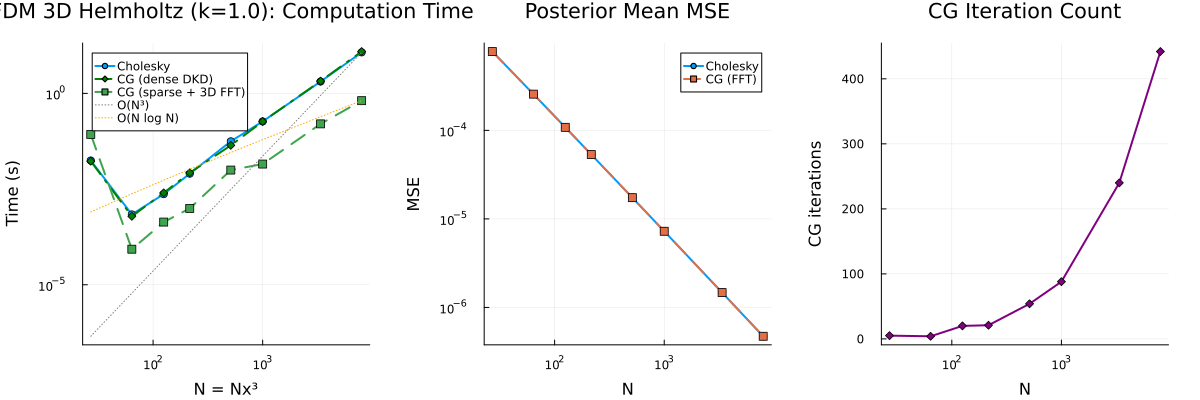

Saved: pfdm_3d_helmholtz_bttb_cg.png


In [10]:
Ns           = [r.N           for r in results]
t_dir        = [r.t_direct    for r in results]
t_cg_dense_v = [r.t_cg_dense  for r in results]
t_cg_v       = [r.t_cg        for r in results]
mse_dir      = [r.mse_direct  for r in results]
mse_cg       = [r.mse_cg      for r in results]
n_iters      = [r.n_iter      for r in results]

mask_dense = .!isnan.(t_cg_dense_v)
Ns_dense   = Ns[mask_dense]
t_dense    = t_cg_dense_v[mask_dense]

p1 = plot(Ns, t_dir;
    marker=:circle, lw=2, label="Cholesky",
    xlabel="N = Nx³", ylabel="Time (s)",
    title="PFDM 3D Helmholtz (k=$(k_wave)): Computation Time",
    yscale=:log10, xscale=:log10, legend=:topleft)
plot!(p1, Ns_dense, t_dense;
    marker=:diamond, lw=2, ls=:dashdot, color=:green,
    label="CG (dense DKD)")
plot!(p1, Ns, t_cg_v;
    marker=:square, lw=2, ls=:dash,
    label="CG (sparse + 3D FFT)")
c3 = t_dir[end] / Ns[end]^3
c1 = t_cg_v[end] / (Ns[end] * log(Ns[end]))
plot!(p1, Ns, c3 .* Ns.^3;          lw=1, ls=:dot, color=:gray,   label="O(N³)")
plot!(p1, Ns, c1 .* Ns .* log.(Ns); lw=1, ls=:dot, color=:orange, label="O(N log N)")

p2 = plot(Ns, mse_dir; marker=:circle, lw=2, label="Cholesky",
    xlabel="N", ylabel="MSE", title="Posterior Mean MSE",
    yscale=:log10, xscale=:log10, legend=:topright)
plot!(p2, Ns, mse_cg; marker=:square, lw=2, ls=:dash, label="CG (FFT)")

p3 = plot(Ns, n_iters; marker=:diamond, lw=2, color=:purple,
    xlabel="N", ylabel="CG iterations", title="CG Iteration Count",
    xscale=:log10, legend=false)

p_all = plot(p1, p2, p3; layout=(1,3), size=(1200,400), margin=6Plots.mm)
display(p_all)
savefig(p_all, "pfdm_3d_helmholtz_bttb_cg.png")
println("Saved: pfdm_3d_helmholtz_bttb_cg.png")


## ハイパーパラメータ選択 (log周辺尤度グリッドサーチ)


In [11]:
function log_marginal_3d(X_all, b, Dh_sp; ν, ℓ, σf, C, τ, dx, k_wave)
    N         = length(b)
    noise_var = C * dx^(2τ)
    K     = [matern_kernel_3d(X_all[i], X_all[j]; ν=ν, ℓ=ℓ, σf=σf)
             for i in 1:N, j in 1:N]
    A     = Dh_sp * K * Dh_sp' + noise_var * I(N) + 1e-10 * I(N)
    L     = cholesky(Hermitian(A)).L
    α     = L' \ (L \ b)
    logdet_A = 2sum(log.(diag(L)))
    return -0.5 * dot(b, α) - 0.5 * logdet_A - 0.5 * N * log(2π)
end

# グリッドサーチ (Nx=5, N=125 で実行)
Nx_hp = 5
Ny_hp = Nx_hp
Nz_hp = Nx_hp
N_hp  = Nx_hp^3
dx_hp = 1.0 / (Nx_hp + 1)
τ_hp  = 2
ν_hp  = 1.5
k_hp  = 1.0

x_hp = range(dx_hp, step=dx_hp, length=Nx_hp)
y_hp = range(dx_hp, step=dx_hp, length=Ny_hp)
z_hp = range(dx_hp, step=dx_hp, length=Nz_hp)
X_hp = [[xi, yj, zl] for zl in z_hp for yj in y_hp for xi in x_hp]
Dh_hp = build_Dh_3d_helmholtz(Nx_hp, Ny_hp, Nz_hp, dx_hp, k_hp)
b_hp  = [f_func(xi, yj, zl, k_hp) for zl in z_hp for yj in y_hp for xi in x_hp]

ℓ_grid  = 10 .^ range(-1, 1, length=8)
σf_grid = 10 .^ range(-2, 1, length=8)
C_grid  = 10 .^ range(-4, 1, length=8)

best_score = -Inf
best_ℓ  = ℓ_grid[1]
best_σf = σf_grid[1]
best_C  = C_grid[1]

for ℓ in ℓ_grid, σf in σf_grid, C_val in C_grid
    score = log_marginal_3d(X_hp, b_hp, Dh_hp;
                ν=ν_hp, ℓ=ℓ, σf=σf, C=C_val, τ=τ_hp, dx=dx_hp, k_wave=k_hp)
    if score > best_score
        best_score = score
        best_ℓ  = ℓ
        best_σf = σf
        best_C  = C_val
    end
end
@printf("best ℓ=%.4g  σf=%.4g  C=%.4g  loglik=%.4g\n",
    best_ℓ, best_σf, best_C, best_score)


best ℓ=1.389  σf=0.5179  C=0.0001  loglik=-394.8


95% CI coverage: 99.5%
max |error|=2.257e-02  max 1.96σ=6.296e-02
Saved: pfdm_3d_helmholtz_solution.png


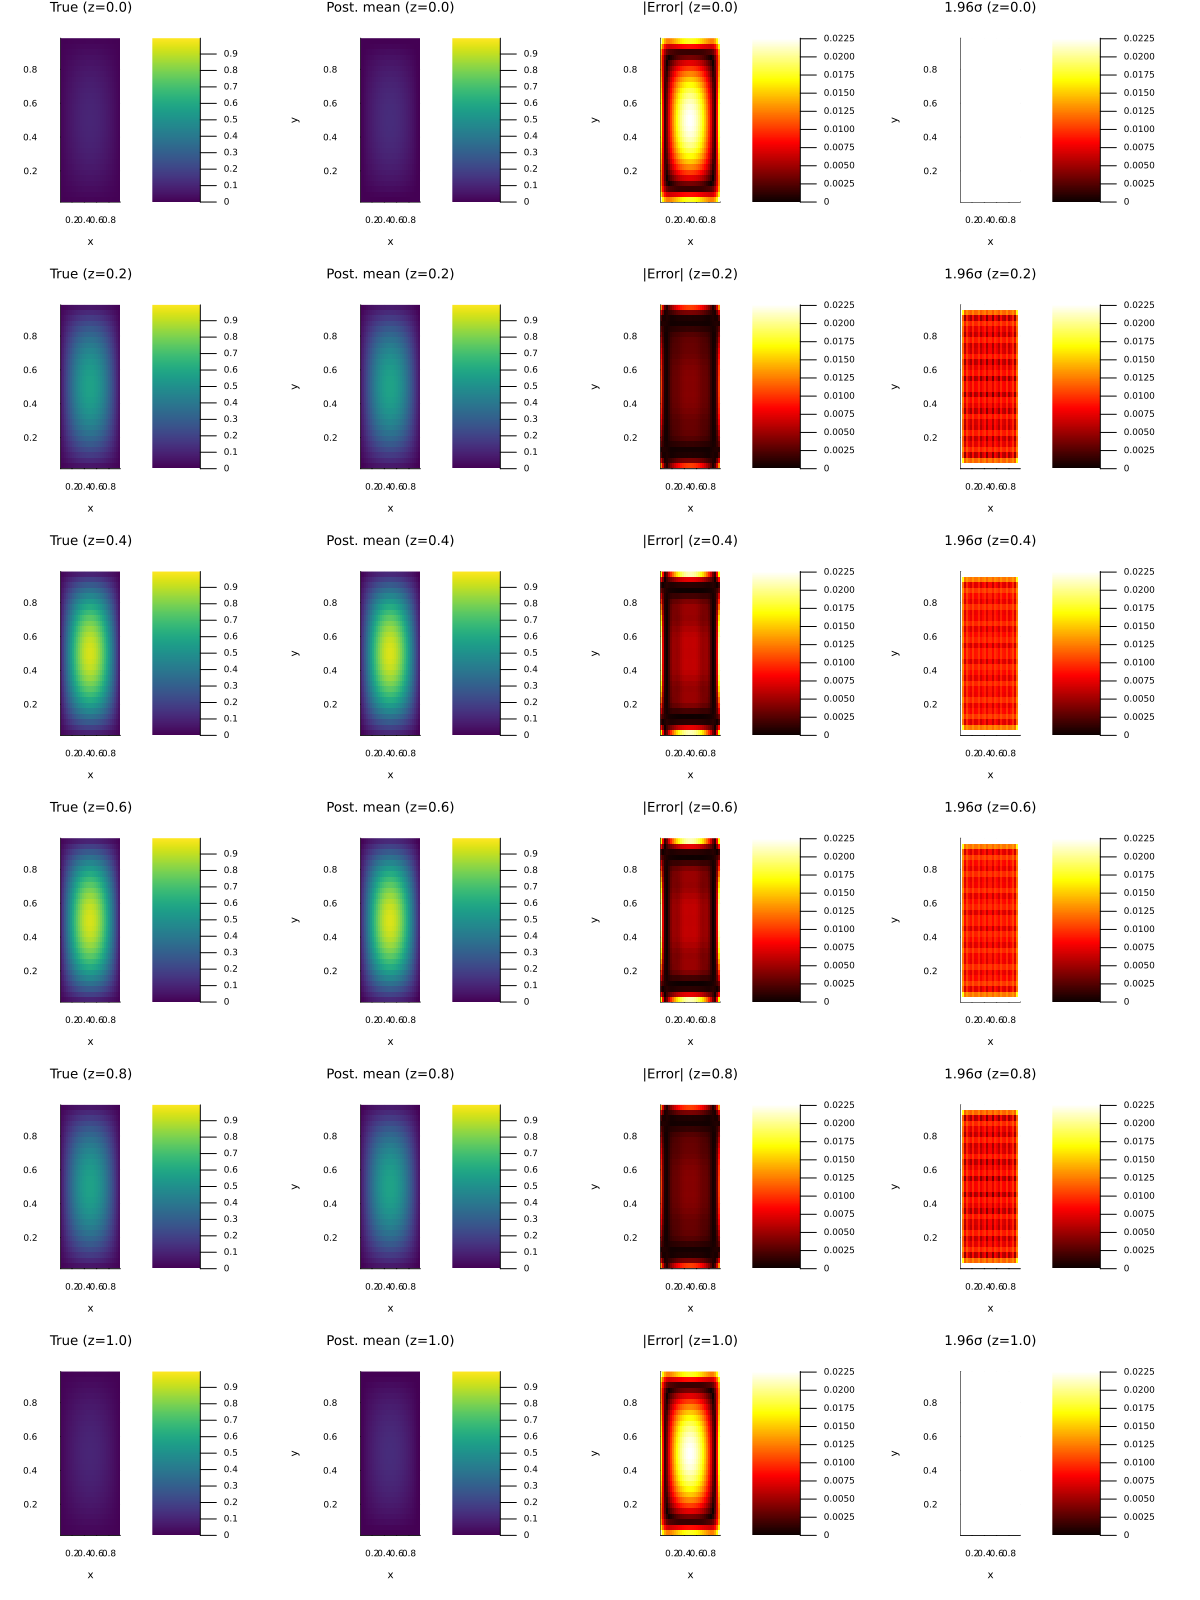

In [14]:
# ============================================================
# 3D可視化: z=0.25, 0.5, 0.75, 1.0付近の4スライス
# 各スライスで True / Posterior mean / |Error| / 1.96σ の4パネル
# 合計 4×4 = 16 パネル
# ============================================================
Nx_v    = 10
Nx_test = 30
N_v     = Nx_v^3
N_test  = Nx_test^3
dx_v    = 1.0 / (Nx_v + 1)
dx_test = 1.0 / (Nx_test + 1)

# 訓練点
x_v = range(dx_v, step=dx_v, length=Nx_v)
y_v = range(dx_v, step=dx_v, length=Nx_v)
z_v = range(dx_v, step=dx_v, length=Nx_v)
X_v = [[xi, yj, zl] for zl in z_v for yj in y_v for xi in x_v]
b_v = [f_func(xi, yj, zl, k_wave) for zl in z_v for yj in y_v for xi in x_v]
Dh_v = build_Dh_3d_helmholtz(Nx_v, Nx_v, Nx_v, dx_v, k_wave)
σ_v  = best_C * dx_v^(2τ)

# テスト点
x_t = range(dx_test, step=dx_test, length=Nx_test)
y_t = range(dx_test, step=dx_test, length=Nx_test)
z_t = range(dx_test, step=dx_test, length=Nx_test)
X_t = [[xi, yj, zl] for zl in z_t for yj in y_t for xi in x_t]
u_tr_t = [u_exact(xi, yj, zl, k_wave) for zl in z_t for yj in y_t for xi in x_t]

# カーネル行列
K_v    = [matern_kernel_3d(X_v[i], X_v[j]; ν=ν, ℓ=best_ℓ, σf=best_σf)
          for i in 1:N_v, j in 1:N_v]
K_star = [matern_kernel_3d(X_t[i], X_v[j]; ν=ν, ℓ=best_ℓ, σf=best_σf)
          for i in 1:N_test, j in 1:N_v]
K_ss_diag = [matern_kernel_3d(X_t[i], X_t[i]; ν=ν, ℓ=best_ℓ, σf=best_σf)
             for i in 1:N_test]

# posterior
A_v  = Dh_v * K_v * Dh_v' + σ_v * I(N_v)
A_ch = cholesky(Hermitian(A_v))
α_v  = A_ch \ b_v
μ_t  = K_star * (Dh_v' * α_v)

DhKs   = Dh_v * K_star'
LiDhKs = A_ch.L \ DhKs
var_t  = max.(K_ss_diag .- vec(sum(LiDhKs.^2, dims=1)), 0.0)
std_t  = sqrt.(var_t)
ci95_t = 1.96 .* std_t

# カバレッジ
coverage = mean(abs.(μ_t .- u_tr_t) .<= ci95_t) * 100
@printf("95%% CI coverage: %.1f%%\n", coverage)
@printf("max |error|=%.3e  max 1.96σ=%.3e\n", maximum(abs.(μ_t .- u_tr_t)), maximum(ci95_t))

# reshape: (Nx_test, Nx_test, Nx_test)
# 並び順: [xi, yj, zl] for zl for yj for xi → reshape(v, Nx, Ny, Nz)
U_tr_3d  = reshape(u_tr_t,              Nx_test, Nx_test, Nx_test)
U_mu_3d  = reshape(μ_t,                 Nx_test, Nx_test, Nx_test)
U_err_3d = reshape(abs.(μ_t .- u_tr_t), Nx_test, Nx_test, Nx_test)
U_ci_3d  = reshape(ci95_t,              Nx_test, Nx_test, Nx_test)

# 4スライスの z インデックス
z_targets = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
z_idxs    = [argmin(abs.(collect(z_t) .- zt)) for zt in z_targets]

# カラースケールを全スライス共通に
clim_sol = (0.0, maximum(U_tr_3d))
#clim_err = (0.0, max(maximum(U_err_3d), maximum(U_ci_3d)))

clim_err = (0.0, maximum(U_err_3d))
clim_ci  = (0.0, maximum(U_ci_3d))

# 4×4 = 16パネル作成
# 行 = スライス (z=0.25, 0.5, 0.75, 1.0)
# 列 = True / Posterior mean / |Error| / 1.96σ
panels = []
for (zi, zt) in zip(z_idxs, z_targets)
    S_tr  = U_tr_3d[:,  :, zi]
    S_mu  = U_mu_3d[:,  :, zi]
    S_err = U_err_3d[:, :, zi]
    S_ci  = U_ci_3d[:,  :, zi]

    h1 = heatmap(collect(x_t), collect(y_t), S_tr';
        color=:viridis, clim=clim_sol,
        title="True (z=$(zt))", xlabel="x", ylabel="y",
        titlefontsize=9, guidefontsize=7, tickfontsize=6)
    h2 = heatmap(collect(x_t), collect(y_t), S_mu';
        color=:viridis, clim=clim_sol,
        title="Post. mean (z=$(zt))", xlabel="x", ylabel="y",
        titlefontsize=9, guidefontsize=7, tickfontsize=6)
    h3 = heatmap(collect(x_t), collect(y_t), S_err';
        color=:hot, clim=clim_err,
        title="|Error| (z=$(zt))", xlabel="x", ylabel="y",
        titlefontsize=9, guidefontsize=7, tickfontsize=6)
    h4 = heatmap(collect(x_t), collect(y_t), S_ci';
        color=:hot, clim=clim_err,
        title="1.96σ (z=$(zt))", xlabel="x", ylabel="y",
        titlefontsize=9, guidefontsize=7, tickfontsize=6)
    push!(panels, h1, h2, h3, h4)
end

fig3d = plot(panels...;
    layout=(6, 4), size=(1200, 1600), margin=3Plots.mm)
display(fig3d)
savefig(fig3d, "pfdm_3d_helmholtz_solution.png")
println("Saved: pfdm_3d_helmholtz_solution.png")


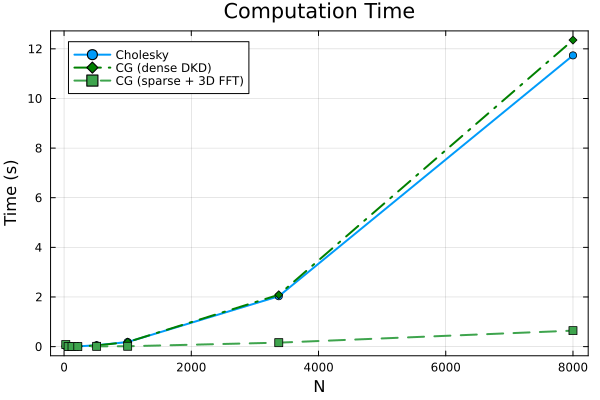

Saved: pfdm_3d_helmholtz_paper.png


In [13]:
# ============================================================
# 論文用: 計算時間 線形スケール
# ============================================================
Ns_plot         = [r.N          for r in results]
t_dir_plot      = [r.t_direct   for r in results]
t_cg_plot       = [r.t_cg       for r in results]
t_cg_dense_plot = [r.t_cg_dense for r in results]

mask_dense_lin = .!isnan.(t_cg_dense_plot)
Ns_dense_lin   = Ns_plot[mask_dense_lin]
t_dense_lin    = t_cg_dense_plot[mask_dense_lin]

p_paper = plot(Ns_plot, t_dir_plot;
    marker=:circle, lw=2, label="Cholesky",
    xlabel="N", ylabel="Time (s)",
    title="Computation Time",
    legend=:topleft, framestyle=:box)
plot!(p_paper, Ns_dense_lin, t_dense_lin;
    marker=:diamond, lw=2, ls=:dashdot, color=:green,
    label="CG (dense DKD)")
plot!(p_paper, Ns_plot, t_cg_plot;
    marker=:square, lw=2, ls=:dash,
    label="CG (sparse + 3D FFT)")

display(p_paper)
savefig(p_paper, "pfdm_3d_helmholtz_paper.png")
println("Saved: pfdm_3d_helmholtz_paper.png")
